In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset (Make sure the filename matches exactly what you uploaded)
# If your file has a different name, change 'KaggleV2-May-2016.csv' to your exact filename
df = pd.read_csv('KaggleV2-May-2016.csv')

# 2. Display the first 5 rows to make sure it loaded properly
df.head()


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [2]:
# Check data types, row counts, and missing values
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  object 
 3   ScheduledDay    110527 non-null  object 
 4   AppointmentDay  110527 non-null  object 
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  object 
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  object 
dtypes: float64(1), int64(8), object(5)
memory usage: 11.8+ MB


In [3]:
# 1. Rename columns to fix typos and standardize to snake_case / lowercase
df.rename(columns={
    'PatientId': 'patient_id',
    'AppointmentID': 'appointment_id',
    'Gender': 'gender',
    'ScheduledDay': 'scheduled_day',
    'AppointmentDay': 'appointment_day',
    'Age': 'age',
    'Neighbourhood': 'neighborhood',
    'Scholarship': 'scholarship',
    'Hipertension': 'hypertension',
    'Diabetes': 'diabetes',
    'Alcoholism': 'alcoholism',
    'Handcap': 'handicap',
    'SMS_received': 'sms_received',
    'No-show': 'no_show'
}, inplace=True)

# 2. Convert date strings into proper datetime format
df['scheduled_day'] = pd.to_datetime(df['scheduled_day'])
df['appointment_day'] = pd.to_datetime(df['appointment_day'])

# 3. Clean up the target column: Convert 'Yes'/'No' to numeric 1 and 0
# Note: In this dataset, 'Yes' means they were a No-Show (missed appointment)
df['no_show'] = df['no_show'].map({'Yes': 1, 'No': 0})

# Verify the changes by printing the new columns and types
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype              
---  ------           --------------   -----              
 0   patient_id       110527 non-null  float64            
 1   appointment_id   110527 non-null  int64              
 2   gender           110527 non-null  object             
 3   scheduled_day    110527 non-null  datetime64[ns, UTC]
 4   appointment_day  110527 non-null  datetime64[ns, UTC]
 5   age              110527 non-null  int64              
 6   neighborhood     110527 non-null  object             
 7   scholarship      110527 non-null  int64              
 8   hypertension     110527 non-null  int64              
 9   diabetes         110527 non-null  int64              
 10  alcoholism       110527 non-null  int64              
 11  handicap         110527 non-null  int64              
 12  sms_received     110527 non-null  int64              
 13 

In [4]:
# Check for impossible ages (negative numbers)
print("Min age:", df['age'].min())
print("Max age:", df['age'].max())

# Count how many appointments were accidentally scheduled before the booking creation date
date_errors = df[df['appointment_day'].dt.date < df['scheduled_day'].dt.date]
print(f"Number of scheduling date errors: {len(date_errors)}")


Min age: -1
Max age: 115
Number of scheduling date errors: 5


In [5]:
# 1. Filter out rows where age is less than 0
df = df[df['age'] >= 0]

# 2. Filter out rows where the appointment date is before the scheduled date
# We use .dt.date to compare just the calendar days
df = df[df['appointment_day'].dt.date >= df['scheduled_day'].dt.date]

# 3. Double-check your numbers to ensure rows were dropped correctly
print(f"Remaining clean records: {df.shape[0]}")
print(f"New minimum age: {df['age'].min()}")


Remaining clean records: 110521
New minimum age: 0


In [6]:
# Calculate the overall baseline no-show rate
total_appointments = len(df)
missed_appointments = df['no_show'].sum()
no_show_rate = (missed_appointments / total_appointments) * 100

print(f"Total Appointments: {total_appointments:,}")
print(f"Total Missed (No-Shows): {missed_appointments:,}")
print(f"Overall No-Show Rate: {no_show_rate:.2f}%")


Total Appointments: 110,521
Total Missed (No-Shows): 22,314
Overall No-Show Rate: 20.19%


/tmp/ipykernel_2214/3825859466.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_2214/3825859466.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


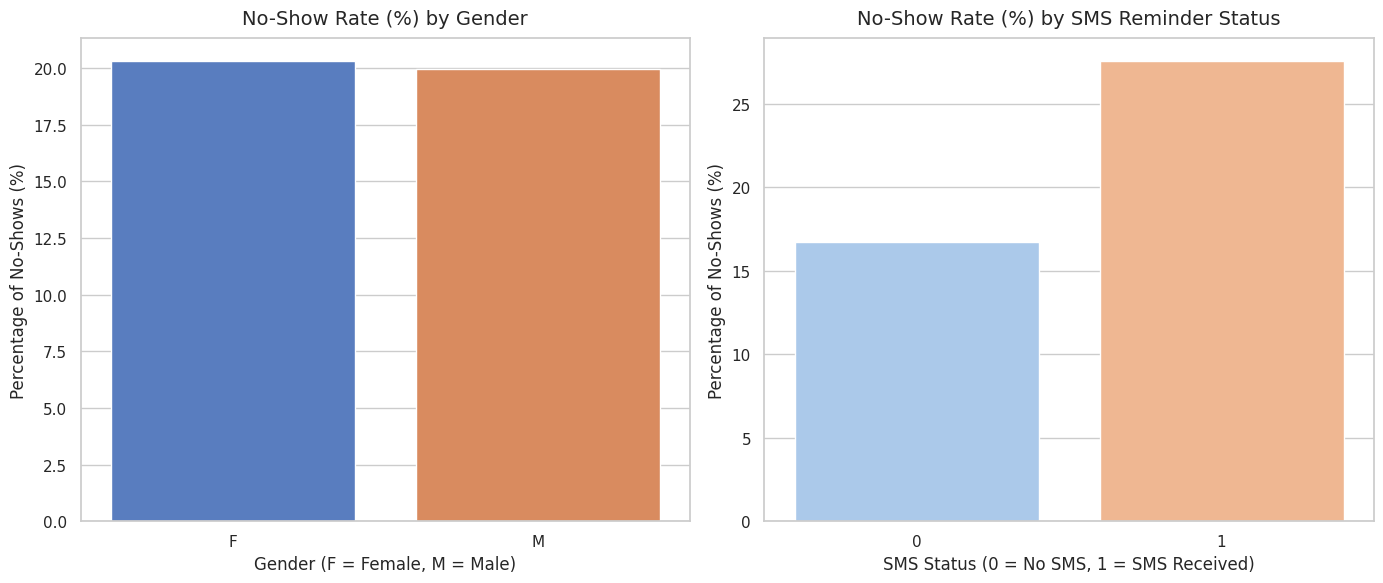

In [7]:
# Set the visual style for our portfolio charts
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Chart 1: No-Show Rate by Gender
sns.barplot(
    x='gender',
    y='no_show',
    data=df,
    ax=axes[0],
    estimator=lambda x: sum(x) / len(x) * 100,
    errorbar=None,
    palette='muted'
)
axes[0].set_title('No-Show Rate (%) by Gender', fontsize=14, pad=10)
axes[0].set_ylabel('Percentage of No-Shows (%)')
axes[0].set_xlabel('Gender (F = Female, M = Male)')

# Chart 2: No-Show Rate by SMS Reminders Received
sns.barplot(
    x='sms_received',
    y='no_show',
    data=df,
    ax=axes[1],
    estimator=lambda x: sum(x) / len(x) * 100,
    errorbar=None,
    palette='pastel'
)
axes[1].set_title('No-Show Rate (%) by SMS Reminder Status', fontsize=14, pad=10)
axes[1].set_ylabel('Percentage of No-Shows (%)')
axes[1].set_xlabel('SMS Status (0 = No SMS, 1 = SMS Received)')

plt.tight_layout()
plt.show()


In [8]:
# Calculate exact no-show percentages grouped by Gender and SMS Status
print("--- No-Show Rate by Gender ---")
print(df.groupby('gender')['no_show'].mean() * 100)

print("\n--- No-Show Rate by SMS Received ---")
print(df.groupby('sms_received')['no_show'].mean() * 100)


--- No-Show Rate by Gender ---
gender
F    20.311543
M    19.963810
Name: no_show, dtype: float64

--- No-Show Rate by SMS Received ---
sms_received
0    16.697984
1    27.574545
Name: no_show, dtype: float64


In [10]:
# 1. Calculate the number of days between scheduling and the actual appointment correctly
df['lead_time'] = (df['appointment_day'].dt.normalize() - df['scheduled_day'].dt.normalize()).dt.days

# 2. Check the average lead time for patients who received an SMS vs those who did not
print("--- Average Lead Time (Days) by SMS Status ---")
print(df.groupby('sms_received')['lead_time'].mean())

# 3. Check the average lead time for No-Shows vs Shows
print("\n--- Average Lead Time (Days) for No-Shows vs Show-Ups ---")
print(df.groupby('no_show')['lead_time'].mean())


--- Average Lead Time (Days) by SMS Status ---
sms_received
0     6.007983
1    19.016713
Name: lead_time, dtype: float64

--- Average Lead Time (Days) for No-Shows vs Show-Ups ---
no_show
0     8.754759
1    15.835484
Name: lead_time, dtype: float64


/tmp/ipykernel_2214/1065360736.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


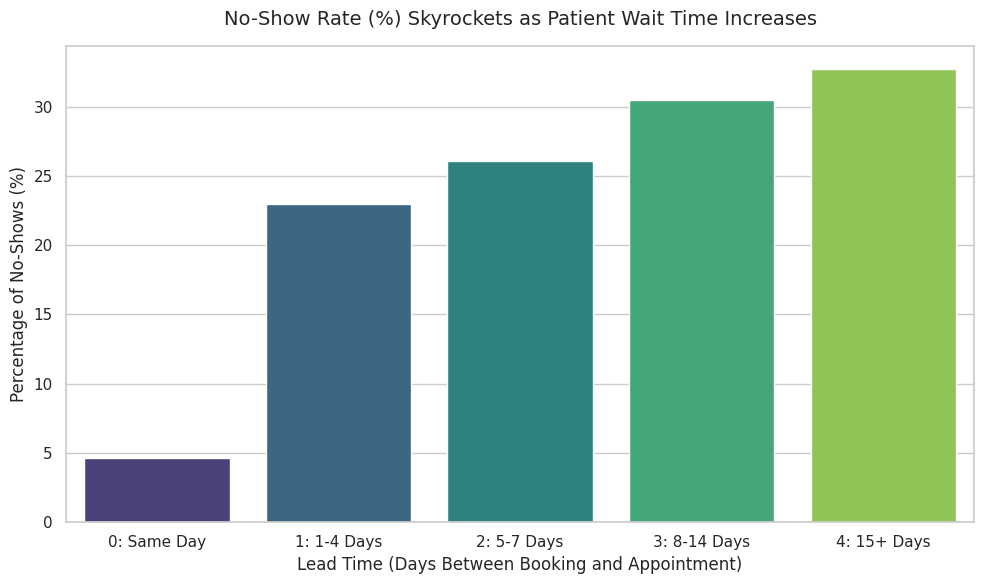

In [11]:
# 1. Create categorical buckets for lead time
def bucket_lead_time(days):
    if days == 0:
        return '0: Same Day'
    elif days <= 4:
        return '1: 1-4 Days'
    elif days <= 7:
        return '2: 5-7 Days'
    elif days <= 14:
        return '3: 8-14 Days'
    else:
        return '4: 15+ Days'

df['lead_time_bucket'] = df['lead_time'].apply(bucket_lead_time)

# 2. Plot the no-show rate for each bucket
plt.figure(figsize=(10, 6))
sns.barplot(
    x='lead_time_bucket',
    y='no_show',
    data=df.sort_values('lead_time_bucket'),
    estimator=lambda x: sum(x) / len(x) * 100,
    errorbar=None,
    palette='viridis'
)

plt.title('No-Show Rate (%) Skyrockets as Patient Wait Time Increases', fontsize=14, pad=15)
plt.ylabel('Percentage of No-Shows (%)', fontsize=12)
plt.xlabel('Lead Time (Days Between Booking and Appointment)', fontsize=12)
plt.tight_layout()
plt.show()


In [12]:
# Save Chart 1: Lead Time Bucket Breakdown
plt.figure(figsize=(10, 6))
sns.barplot(
    x='lead_time_bucket',
    y='no_show',
    data=df.sort_values('lead_time_bucket'),
    estimator=lambda x: sum(x) / len(x) * 100,
    errorbar=None,
    palette='viridis'
)
plt.title('No-Show Rate (%) Skyrockets as Patient Wait Time Increases', fontsize=14, pad=15)
plt.ylabel('Percentage of No-Shows (%)', fontsize=12)
plt.xlabel('Lead Time (Days Between Booking and Appointment)', fontsize=12)
plt.tight_layout()
plt.savefig('lead_time_analysis.png', dpi=300)
plt.close()

# Save Chart 2: SMS & Gender Overview (Combining our previous analysis into one image)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x='gender', y='no_show', data=df, ax=axes[0], estimator=lambda x: sum(x)/len(x)*100, errorbar=None, palette='muted')
axes[0].set_title('No-Show Rate (%) by Gender')
axes[0].set_ylabel('Percentage of No-Shows (%)')
sns.barplot(x='sms_received', y='no_show', data=df, ax=axes[1], estimator=lambda x: sum(x)/len(x)*100, errorbar=None, palette='pastel')
axes[1].set_title('No-Show Rate (%) by SMS Status')
axes[1].set_ylabel('Percentage of No-Shows (%)')
plt.tight_layout()
plt.savefig('gender_sms_analysis.png', dpi=300)
plt.close()

print("Charts successfully saved!")


/tmp/ipykernel_2214/2802607267.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_2214/2802607267.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='gender', y='no_show', data=df, ax=axes[0], estimator=lambda x: sum(x)/len(x)*100, errorbar=None, palette='muted')
/tmp/ipykernel_2214/2802607267.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='sms_received', y='no_show', data=df, ax=axes[1], estimator=lambda x: sum(x)/len(x)*100, errorbar=None, palette='pastel')


Charts successfully saved!
